In [1]:

import pandas as pd

data = {
    "Date": [
        "2026-01-05", "2026-01-12", "2026-02-03",
        "2026-02-15", "2026-03-02", "2026-03-18",
        "2026-04-06", "2026-04-21"
    ],
    "Product": [
        "Laptop", "Mouse", "Laptop", "Keyboard",
        "Mouse", "Laptop", "Keyboard", "Mouse"
    ],
    "Quantity": [2, 10, 1, 5, 8, 3, 4, 12],
    "Price": [50000, 500, 50000, 1500, 500, 50000, 1500, 500]
}

df = pd.DataFrame(data)
df["Date"] = pd.to_datetime(df["Date"])
df["Revenue"] = df["Quantity"] * df["Price"]

df

,Date,Product,Quantity,Price,Revenue
0,2026-01-05,Laptop,2,50000,100000
1,2026-01-12,Mouse,10,500,5000
2,2026-02-03,Laptop,1,50000,50000
3,2026-02-15,Keyboard,5,1500,7500
4,2026-03-02,Mouse,8,500,4000
5,2026-03-18,Laptop,3,50000,150000
6,2026-04-06,Keyboard,4,1500,6000
7,2026-04-21,Mouse,12,500,6000


In [2]:

print("Total Transactions:", len(df))
print("Total Quantity Sold:", df["Quantity"].sum())
print("Total Sales Revenue: ₹", df["Revenue"].sum())

Total Transactions: 8
Total Quantity Sold: 45
Total Sales Revenue: ₹ 328500


In [3]:

product_sales = df.groupby("Product")["Revenue"].sum()

print("Revenue by Product:")
print(product_sales)

print("\nBest Product by Revenue:")
print(product_sales.idxmax())

print("Highest Revenue: ₹", product_sales.max())

Revenue by Product:
Product
Keyboard     13500
Laptop      300000
Mouse        15000
Name: Revenue, dtype: int64

Best Product by Revenue:
Laptop
Highest Revenue: ₹ 300000


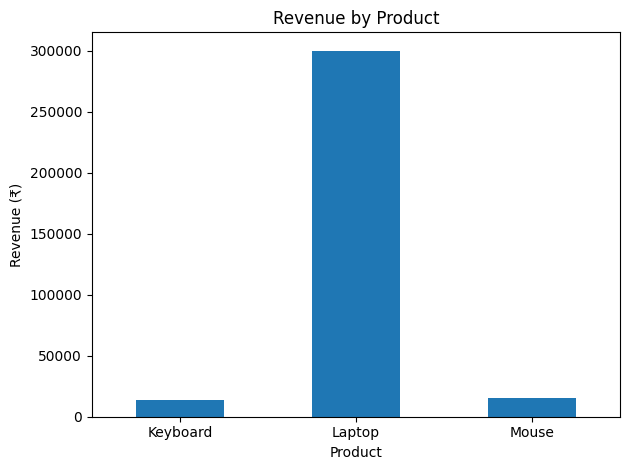

In [4]:

import matplotlib.pyplot as plt

product_sales = df.groupby("Product")["Revenue"].sum()

product_sales.plot(kind="bar", title="Revenue by Product")

plt.xlabel("Product")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [5]:

monthly_sales = df.groupby(
    df["Date"].dt.to_period("M")
)["Revenue"].sum()

print("Monthly Sales Revenue:")
print(monthly_sales)

Monthly Sales Revenue:
Date
2026-01    105000
2026-02     57500
2026-03    154000
2026-04     12000
Freq: M, Name: Revenue, dtype: int64


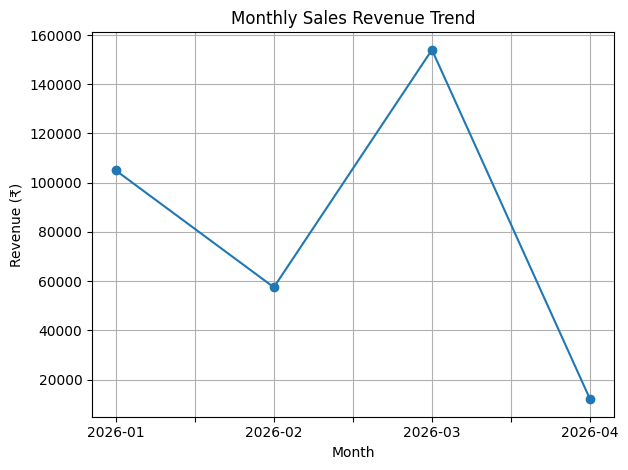

In [6]:

import matplotlib.pyplot as plt

monthly_sales = df.groupby(
    df["Date"].dt.to_period("M")
)["Revenue"].sum()

monthly_sales.index = monthly_sales.index.astype(str)

monthly_sales.plot(
    kind="line",
    marker="o",
    title="Monthly Sales Revenue Trend"
)

plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.grid(True)
plt.tight_layout()
plt.show()